# Iris Flower Classification
Internship Task 1 - Machine Learning

Classifying iris flowers into 3 species using their sepal and petal measurements.

## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## 2. Load the Dataset
Loading the iris dataset from scikit-learn into a pandas DataFrame.

In [2]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (150, 5)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.1 KB


In [5]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [6]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [7]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

## 3. Exploratory Data Analysis
Plotting the features to see distributions and relationships between species.

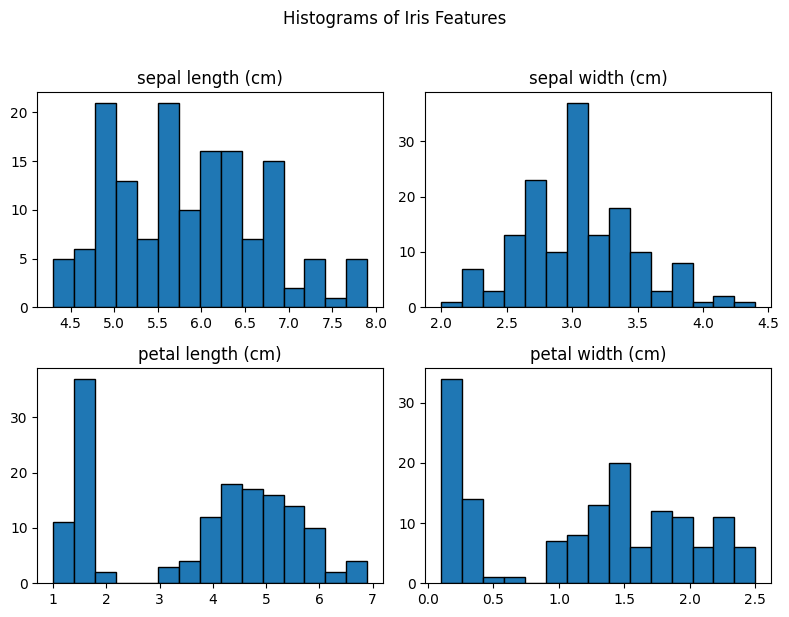

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(8, 6))
df[iris.feature_names].hist(ax=axes, bins=15, edgecolor='black', grid=False)
plt.suptitle('Histograms of Iris Features', y=1.02)
plt.tight_layout()
plt.show()

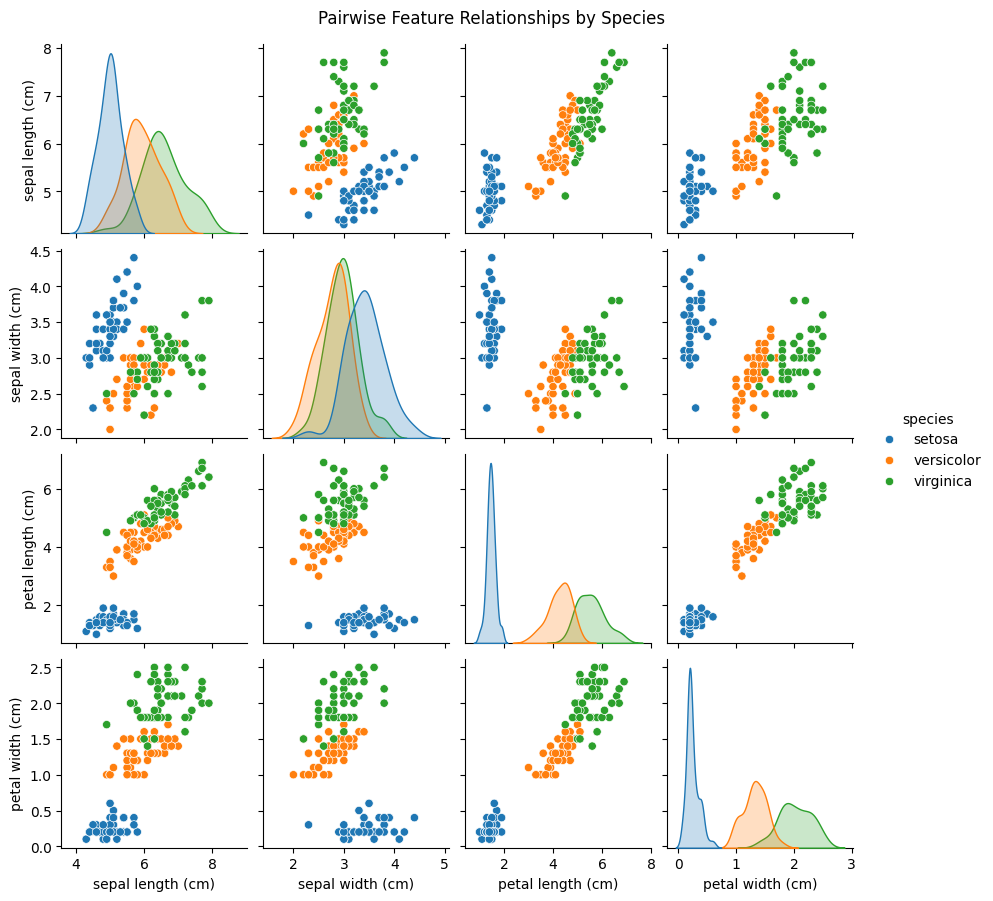

In [9]:
sns.pairplot(df, hue='species', height=2.2)
plt.suptitle('Pairwise Feature Relationships by Species', y=1.02)
plt.show()

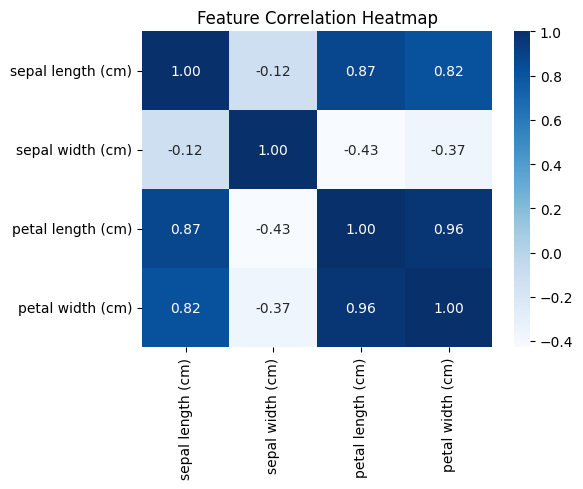

In [10]:
plt.figure(figsize=(6, 5))
corr_matrix = df[iris.feature_names].corr()
sns.heatmap(corr_matrix, annot=True, cmap='Blues', fmt='.2f', cbar=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

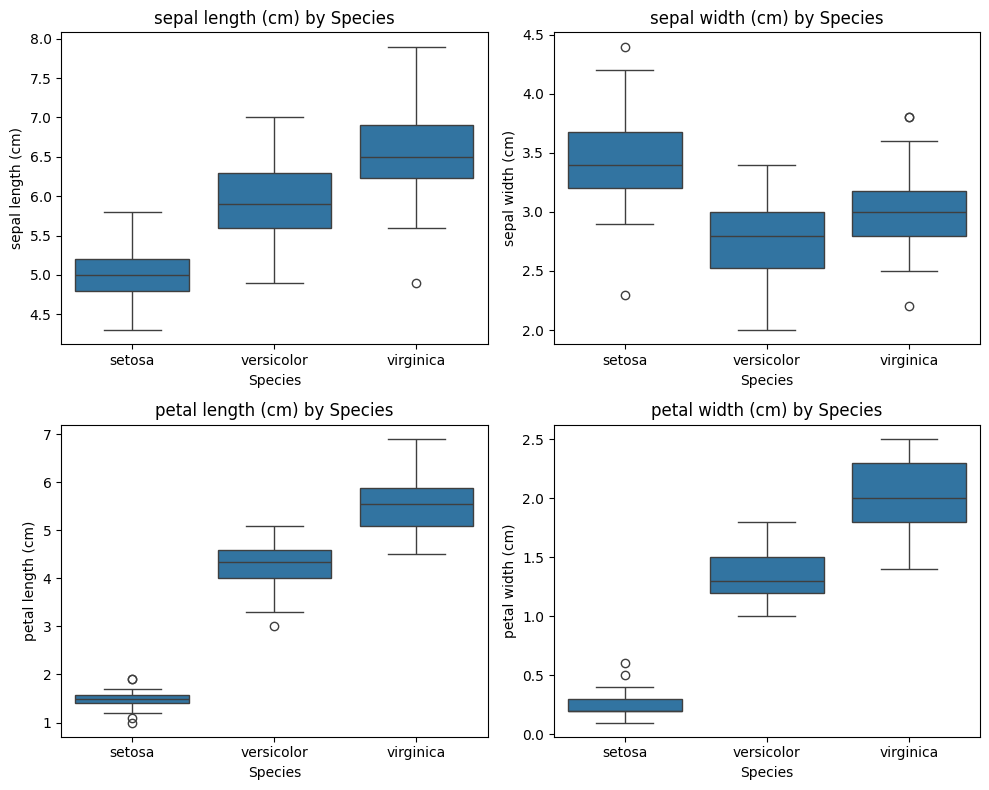

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for i, feature in enumerate(iris.feature_names):
    ax = axes[i // 2, i % 2]
    sns.boxplot(x='species', y=feature, data=df, ax=ax)
    ax.set_title(f'{feature} by Species')
    ax.set_xlabel('Species')
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Key Observations from EDA
- setosa is clearly separable from the other two species, especially by petal length and petal width.
- versicolor and virginica have some overlap, particularly in sepal length and sepal width.
- Petal length and petal width are highly correlated (0.96), making them the most useful features for separating species.
- Sepal measurements are more spread out across all three species.

## 4. Preprocessing
The dataset has no missing values. Splitting 80/20 with stratification and scaling with StandardScaler.

In [12]:
X = df[iris.feature_names]
y = df['species']

# 80/20 stratified split to preserve class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Fit scaler only on train to prevent data leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training samples: {X_train.shape[0]}")
print(f"Test samples: {X_test.shape[0]}")

Training samples: 120
Test samples: 30


## 5. Model Training
Training Logistic Regression, KNN (k=5), and a Decision Tree (max_depth=3).

In [13]:
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

LogisticRegression(random_state=42)

In [14]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [15]:
# Decision trees do not need feature scaling, but using scaled data for consistency
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

## 6. Evaluation
Evaluating the models on the test set and checking 5-fold cross-validation.

In [16]:
models = {
    'Logistic Regression': lr_model,
    'K-Nearest Neighbors': knn_model,
    'Decision Tree': dt_model
}

predictions = {}
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='macro')
    rec = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')
    
    print(f"=== {name} ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"Macro F1:  {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))
    print("-" * 50)

=== Logistic Regression ===
Accuracy:  0.9333
Precision: 0.9333
Recall:    0.9333
Macro F1:  0.9333

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

--------------------------------------------------
=== K-Nearest Neighbors ===
Accuracy:  0.9333
Precision: 0.9444
Recall:    0.9333
Macro F1:  0.9327

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93     

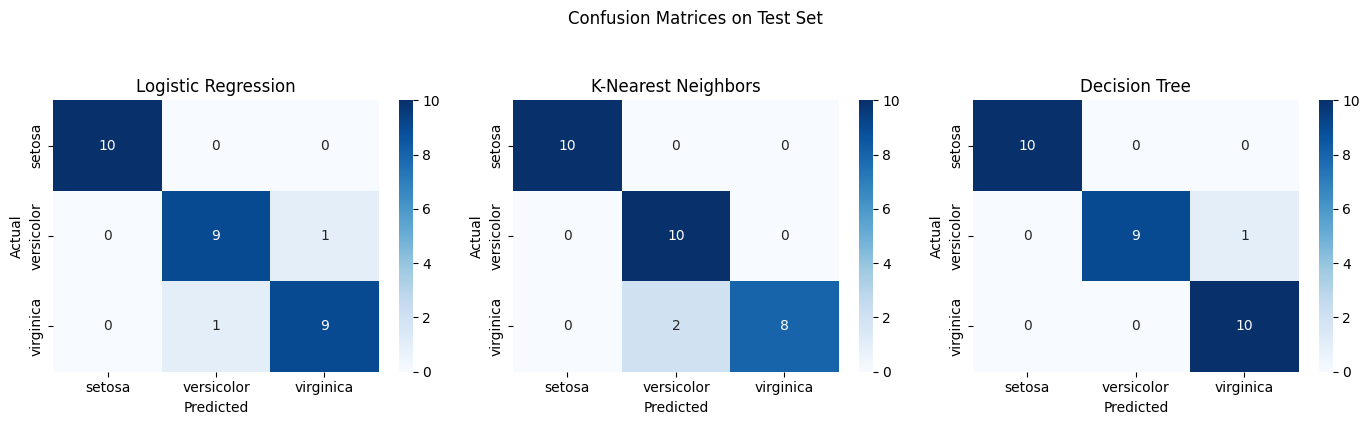

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
class_names = iris.target_names

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_names)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices on Test Set', y=1.05)
plt.tight_layout()
plt.show()

In [18]:
summary_rows = []
for name, y_pred in predictions.items():
    summary_rows.append({
        'Model': name,
        'Test Accuracy': accuracy_score(y_test, y_pred),
        'Macro F1': f1_score(y_test, y_pred, average='macro')
    })

comparison_df = pd.DataFrame(summary_rows)
comparison_df

,Model,Test Accuracy,Macro F1
0,Logistic Regression,0.933333,0.933333
1,K-Nearest Neighbors,0.933333,0.932660
2,Decision Tree,0.966667,0.966583


In [19]:
# 5-fold cross-validation using a pipeline to scale inside each fold and avoid data leakage
cv_rows = []
print("5-Fold Cross-Validation Scores:")
for name, model in models.items():
    cv_scores = cross_val_score(make_pipeline(StandardScaler(), model), X, y, cv=5)
    print(f"{name}: Mean = {cv_scores.mean():.4f}, Std = {cv_scores.std():.4f}")
    cv_rows.append({
        'Model': name,
        'CV Mean Accuracy': cv_scores.mean(),
        'CV Std': cv_scores.std()
    })

cv_df = pd.DataFrame(cv_rows)
cv_df

5-Fold Cross-Validation Scores:
Logistic Regression: Mean = 0.9600, Std = 0.0389
K-Nearest Neighbors: Mean = 0.9600, Std = 0.0249
Decision Tree: Mean = 0.9733, Std = 0.0249


,Model,CV Mean Accuracy,CV Std
0,Logistic Regression,0.960000,0.038873
1,K-Nearest Neighbors,0.960000,0.024944
2,Decision Tree,0.973333,0.024944


## 7. KNN: trying different k values
Checking test accuracy for different values of k from 1 to 15.

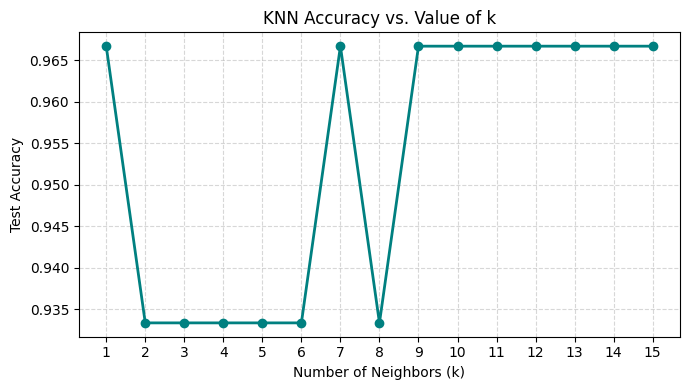

In [20]:
k_range = list(range(1, 16))
k_scores = []

for k in k_range:
    temp_knn = KNeighborsClassifier(n_neighbors=k)
    temp_knn.fit(X_train_scaled, y_train)
    k_scores.append(temp_knn.score(X_test_scaled, y_test))

plt.figure(figsize=(7, 4))
plt.plot(k_range, k_scores, marker='o', color='teal', linewidth=2)
plt.title('KNN Accuracy vs. Value of k')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Test Accuracy')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Testing k on the test set gave 96.67% accuracy at k = 7 compared to 93.33% at k = 5. Because k was compared directly on the test set, this result is slightly optimistic. Also, the difference between 93.33% and 96.67% is only one sample out of 30.

## 8. Predict on a New Sample
Testing a prediction on a new sample using the trained model.

In [21]:
# A sample I made up
new_sample = pd.DataFrame([[5.8, 2.7, 4.1, 1.2]], columns=iris.feature_names)

new_sample_scaled = scaler.transform(new_sample)

predicted_species = lr_model.predict(new_sample_scaled)[0]
print(f"Input measurements: {new_sample.iloc[0].to_dict()}")
print(f"Predicted species: {predicted_species}")

Input measurements: {'sepal length (cm)': 5.8, 'sepal width (cm)': 2.7, 'petal length (cm)': 4.1, 'petal width (cm)': 1.2}
Predicted species: versicolor


## 9. Conclusion
- The three models perform about the same on the test set, with the Decision Tree slightly ahead at 96.67% accuracy compared to 93.33% for Logistic Regression and KNN, though with only 30 test samples one wrong prediction changes accuracy by about 3.3%.
- setosa was never misclassified by any model, and all mistakes were between versicolor and virginica because their petal ranges overlap.
- The 5-fold cross-validation scores (96.00% for Logistic Regression and KNN, and 97.33% for Decision Tree) show that the results are not just from one split.
- Comparing k values for KNN showed that k=7 reached 96.67% accuracy, but comparing k on the test set is slightly optimistic and the gain over k=5 is only one sample out of 30.
- A useful improvement would be repeating the split with different random seeds or testing on a bigger dataset to confirm stability.